# Monte Carlo y validación: MEGC walrasiano y SVAR

Este notebook somete los dos modelos de la investigación a experimentos de Monte Carlo y a pruebas de validación, **por separado**, porque son modelos de naturaleza distinta:

| | MEGC walrasiano (`stargate_cge.ipynb`) | SVAR (`var_enfermedad_holandesa.ipynb`) |
|---|---|---|
| Naturaleza | Calibrado y determinístico | Estimado con datos, estocástico |
| Fuente de incertidumbre | Parámetros calibrados y supuestos | Error muestral de la estimación |
| Monte Carlo | Muestreo de parámetros (hipercubo latino) | Simulación desde el proceso estimado |
| "Significatividad" | Probabilidad de signo e intervalos de incertidumbre | Pruebas de hipótesis clásicas, tamaño y potencia |
| "Ajuste" | Replicación del año base, Walras, unicidad del equilibrio | Pruebas F, diagnóstico de residuos, estabilidad y pronóstico fuera de muestra |

Un MEGC calibrado no tiene error muestral: con los mismos parámetros siempre da el mismo resultado. Aplicarle una prueba t a sus simulaciones no tiene sentido, porque con suficientes réplicas cualquier diferencia "es significativa". Su validación consiste en medir **qué tan robustas son sus conclusiones a la incertidumbre de los supuestos**.

In [1]:
import io
import time
import urllib.request
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator, PercentFormatter
from scipy import stats
from scipy.optimize import root
from scipy.stats import qmc
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.api import VAR

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*p-value.*")

SEMILLA = 42
N_MEGC = 2000          # sorteos de parámetros del MEGC
N_INICIOS = 300        # puntos iniciales aleatorios para la prueba de unicidad
N_MC_SESGO = 1000      # réplicas para el sesgo del estimador del SVAR
N_MC_POTENCIA = 1000   # réplicas por tamaño de efecto en la curva de potencia
H = 20                 # horizonte de las respuestas del SVAR (trimestres)
CAPEX = 18.9           # USD bn, inversión de Stargate

AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA2, GRILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "axes.titlelocation": "left",
    "font.size": 9, "lines.linewidth": 2, "legend.frameon": False,
})

---
# Parte I · MEGC walrasiano

## I.1 Carga del modelo

In [2]:
# Carga del MEGC: stargate_cge.ipynb tiene que estar en la misma carpeta que este notebook.
# En Google Colab cada notebook se abre solo (en /content), así que si falta se pide subirlo.
from pathlib import Path

MODELO = Path("stargate_cge.ipynb")
if not MODELO.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(
            f"No se encontró {MODELO.resolve()}. Abrí este notebook desde la carpeta que contiene stargate_cge.ipynb."
        ) from None
    print("No se encontró stargate_cge.ipynb. Subilo con el botón de abajo:")
    subidos = [n for n in files.upload() if n.endswith(".ipynb")]
    if not subidos:
        raise FileNotFoundError("No se subió ningún .ipynb con el modelo.")
    Path(subidos[0]).rename(MODELO)  # Colab renombra duplicados como "stargate_cge (1).ipynb"

%run stargate_cge.ipynb

In [3]:
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)  # textos completos en las tablas
cal_central = calibrar(EconomiaBase(), ShockDatacenter())
print("Modelo cargado. Precio base de la energía:", f"{1000 * cal_central['pE0']:.2f} USD/MWh")

Modelo cargado. Precio base de la energía: 67.03 USD/MWh


## I.2 Distribuciones de los parámetros

Los parámetros empíricos del proyecto (CapEx de USD 18.900 M, 4,55 TWh, USD 305 M) quedan **fijos**, como en la investigación. Se sortean los parámetros calibrados y los supuestos, con distribuciones uniformes en rangos plausibles. Se usa **muestreo por hipercubo latino**, que cubre el espacio de parámetros de forma más pareja que el muestreo aleatorio simple con el mismo número de sorteos.

| Parámetro | Rango | Fundamento del rango |
|---|---|---|
| PBI (USD bn) | 600 – 680 | ±6% alrededor de 640; incertidumbre del tipo de cambio de conversión |
| Demanda eléctrica (TWh) | 130 – 150 | CAMMESA: 138,8 TWh en 2022, con crecimiento posterior |
| Electricidad usada por empresas | 0,50 – 0,60 | Residencial ≈ 46% según CAMMESA |
| Participación del trabajo en el PBI | 0,43 – 0,57 | INDEC: asalariados ≈ 43–44%; con ingreso mixto ≈ 57% |
| Participación del trabajo en energía (α) | 0,10 – 0,30 | Generación intensiva en capital |
| Elasticidad de la oferta laboral | 0,00 – 0,50 | De oferta fija a elasticidad moderada |
| Masa salarial del datacenter (USD bn) | 0,03 – 0,12 | ≈ 750 a 3.000 puestos de USD 40k |
| Costo de uso del hardware (r* + δ) | 0,15 – 0,35 | Vida útil del hardware de 4 a 8 años |
| Margen del datacenter | 1,00 – 1,40 | De beneficio nulo a margen alto |

In [4]:
RANGOS = {  # parámetro: (dataclass, mínimo, máximo)
    "pbi": ("eco", 600, 680),
    "demanda_electrica_twh": ("eco", 130, 150),
    "share_electricidad_resto": ("eco", 0.50, 0.60),
    "share_trabajo_pbi": ("eco", 0.43, 0.57),
    "share_trabajo_energia": ("eco", 0.10, 0.30),
    "elasticidad_oferta_laboral": ("eco", 0.00, 0.50),
    "masa_salarial_usd_bn": ("dc", 0.03, 0.12),
    "costo_uso_capital": ("dc", 0.15, 0.35),
    "markup": ("dc", 1.00, 1.40),
}
lhs = qmc.LatinHypercube(d=len(RANGOS), seed=SEMILLA)
muestras = pd.DataFrame(qmc.scale(lhs.random(N_MEGC), [v[1] for v in RANGOS.values()], [v[2] for v in RANGOS.values()]),
                        columns=list(RANGOS))
muestras.describe().T[["mean", "min", "max"]]

,mean,min,max
pbi,639.9996,600.0362,679.9741
demanda_electrica_twh,139.9999,130.0091,149.9957
share_electricidad_resto,0.5500,0.5000,0.6000
share_trabajo_pbi,0.5000,0.4300,0.5700
share_trabajo_energia,0.2000,0.1001,0.3000
elasticidad_oferta_laboral,0.2500,0.0000,0.4998
masa_salarial_usd_bn,0.0750,0.0300,0.1200
costo_uso_capital,0.2500,0.1501,0.3499
markup,1.2000,1.0000,1.3999


## I.3 Ejecución del Monte Carlo

Para cada sorteo se recalibra el modelo y se resuelven tres equilibrios: base sin datacenter, corto plazo y largo plazo. En cada uno se registran los resultados y tres controles de validez: replicación del año base, ley de Walras y residuo del solver.

In [5]:
def correr_megc(fila):
    eco = replace(EconomiaBase(), **{k: fila[k] for k, v in RANGOS.items() if v[0] == "eco"})
    dc = replace(ShockDatacenter(), **{k: fila[k] for k, v in RANGOS.items() if v[0] == "dc"})
    c = calibrar(eco, dc)
    esc = {"Base": resolver(c, "largo", con_dc=False),
           "Corto plazo": resolver(c, "corto", con_dc=True),
           "Largo plazo": resolver(c, "largo", con_dc=True)}
    t = tabla_resultados(c, esc)
    b0, cp = esc["Base"], esc["Corto plazo"]
    return {
        "Δ% p_E corto plazo": t.loc["p_E (USD/MWh)", "Δ% Corto plazo"],
        "Δ% p_E largo plazo": t.loc["p_E (USD/MWh)", "Δ% Largo plazo"],
        "Δ% generación corto plazo": t.loc["X_E generación (TWh)", "Δ% Corto plazo"],
        "Δ% generación largo plazo": t.loc["X_E generación (TWh)", "Δ% Largo plazo"],
        "Δ% producto del resto largo plazo": t.loc["X_R resto (USD bn)", "Δ% Largo plazo"],
        "Δ% PBI largo plazo": t.loc["PBI (USD bn)", "Δ% Largo plazo"],
        "Factura eléctrica DC corto plazo (USD M)": t.loc["Factura eléctrica DC (USD M)", "Corto plazo"],
        "Desplazamiento de consumo corto plazo (% de E_D)": 100 * ((b0["ER"] + b0["CE"]) - (cp["ER"] + cp["CE"])) / cp["ED"],
        "Variación equivalente corto plazo (USD bn)": t.loc["Variación equivalente (USD bn)", "Corto plazo"],
        "Variación equivalente largo plazo (USD bn)": t.loc["Variación equivalente (USD bn)", "Largo plazo"],
        "_replica_base": max(abs(b0["pE"] / c["pE0"] - 1), abs(b0["w"] - 1), abs(b0["XE"] / c["XE0"] - 1)),
        "_walras": max(abs(t.loc["Chequeo Walras (≈0)", k]) for k in ("Corto plazo", "Largo plazo")),
        "_residuo": t.loc["Máx. residuo solver"].iloc[:3].max(),
    }


t0 = time.time()
filas, fallas = [], 0
for _, fila in muestras.iterrows():
    try:
        filas.append(correr_megc(fila))
    except RuntimeError:
        filas.append({})
        fallas += 1
mc = pd.DataFrame(filas, index=muestras.index)
print(f"{N_MEGC} sorteos en {time.time() - t0:.1f} s; sin convergencia: {fallas}")

2000 sorteos en 10.1 s; sin convergencia: 0


## I.4 Validación numérica en todo el espacio de parámetros

Se repiten, para **cada** sorteo, las pruebas que `test_cge.ipynb` aplica a la calibración central:
- **Replicación del año base:** desvío máximo < 10<sup>-6</sup>.
- **Ley de Walras:** residuo < 10<sup>-8</sup>.
- **Convergencia del solver:** residuo < 10<sup>-10</sup>.

Si fallan en alguna región del espacio de parámetros, el modelo no es confiable en esa región.

In [6]:
ok = mc.dropna(subset=["_residuo"])
validacion = pd.DataFrame({
    "Criterio": ["Desvío < 1e-6", "|residuo| < 1e-8", "Residuo < 1e-10", "El solver converge"],
    "Sorteos que aprueban (%)": [100 * (ok["_replica_base"] < 1e-6).mean(), 100 * (ok["_walras"] < 1e-8).mean(),
                                 100 * (ok["_residuo"] < 1e-10).mean(), 100 * len(ok) / N_MEGC],
    "Peor caso": [ok["_replica_base"].max(), ok["_walras"].max(), ok["_residuo"].max(), np.nan],
}, index=["Replicación del año base", "Ley de Walras", "Residuo del solver", "Convergencia"])
validacion

,Criterio,Sorteos que aprueban (%),Peor caso
Replicación del año base,Desvío < 1e-6,100.0000,0.0000
Ley de Walras,|residuo| < 1e-8,100.0000,0.0000
Residuo del solver,Residuo < 1e-10,100.0000,0.0000
Convergencia,El solver converge,100.0000,NaN


## I.5 Distribución de los resultados

Para cada resultado: media, desvío, percentiles 5, 50 y 95, y **probabilidad de que sea positivo**. La columna "Signo robusto" indica si el intervalo del 90% excluye el cero; es el equivalente, para un modelo calibrado, de un efecto "significativo": la conclusión no depende de los supuestos dentro de los rangos considerados. El error estándar de Monte Carlo mide la precisión numérica de la media estimada.

In [7]:
salidas = [c for c in mc.columns if not c.startswith("_")]
valores = ok[salidas]
central = pd.Series(correr_megc(pd.Series({k: getattr(EconomiaBase(), k) if v[0] == "eco" else getattr(ShockDatacenter(), k)
                                             for k, v in RANGOS.items()})))[salidas]
resumen_megc = pd.DataFrame({
    "Valor central": central,
    "Media": valores.mean(),
    "Desvío": valores.std(),
    "P5": valores.quantile(0.05),
    "P50": valores.median(),
    "P95": valores.quantile(0.95),
    "P(> 0)": (valores > 0).mean(),
    "Error est. MC": valores.std() / np.sqrt(len(valores)),
})
resumen_megc["Signo robusto (90%)"] = np.where((resumen_megc["P5"] > 0) | (resumen_megc["P95"] < 0), "sí", "no")
resumen_megc

,Valor central,Media,Desvío,P5,P50,P95,P(> 0),Error est. MC,Signo robusto (90%)
Δ% p_E corto plazo,2.6565,2.6608,0.2292,2.2945,2.6554,3.0494,1.0000,0.0051,sí
Δ% p_E largo plazo,0.0059,0.0047,0.0070,-0.0059,0.0040,0.0178,0.7470,0.0002,no
Δ% generación corto plazo,0.6557,0.6552,0.1901,0.3634,0.6592,0.9564,1.0000,0.0043,sí
Δ% generación largo plazo,3.2205,3.2247,0.1351,3.0218,3.2194,3.4433,1.0000,0.0030,sí
Δ% producto del resto largo plazo,-0.0675,-0.0712,0.0099,-0.0901,-0.0697,-0.0575,0.0000,0.0002,sí
Δ% PBI largo plazo,0.8875,0.8875,0.2235,0.5564,0.8830,1.2737,1.0000,0.0050,sí
Factura eléctrica DC corto plazo (USD M),313.1024,313.1155,0.6991,311.9984,313.0990,314.3008,1.0000,0.0156,sí
Desplazamiento de consumo corto plazo (% de E_D),79.8242,79.8736,5.7716,70.9246,79.8860,88.8667,1.0000,0.1291,sí
Variación equivalente corto plazo (USD bn),0.2565,0.2564,0.1603,0.0281,0.2404,0.5483,1.0000,0.0036,sí
Variación equivalente largo plazo (USD bn),0.2545,0.2544,0.1603,0.0259,0.2384,0.5463,1.0000,0.0036,sí


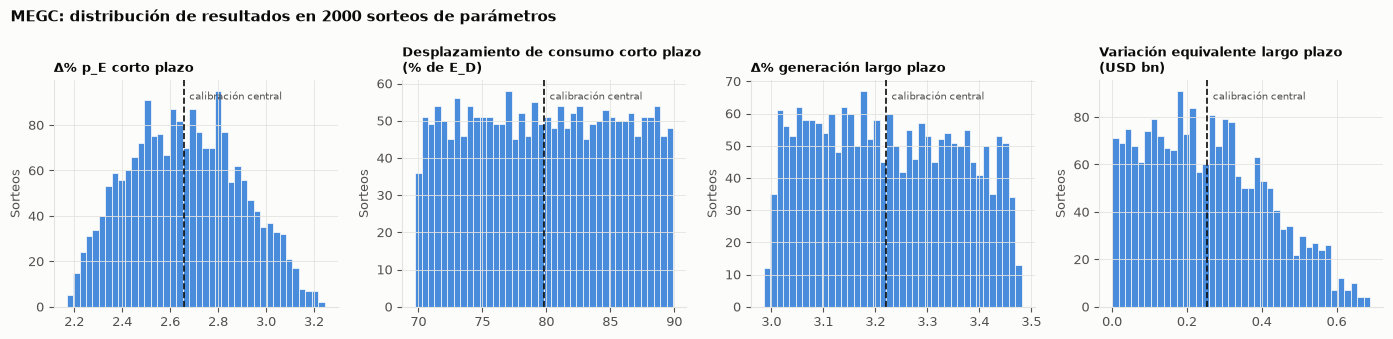

In [8]:
claves = ["Δ% p_E corto plazo", "Desplazamiento de consumo corto plazo (% de E_D)",
          "Δ% generación largo plazo", "Variación equivalente largo plazo (USD bn)"]
fig, ejes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, k in zip(ejes, claves):
    ax.hist(valores[k], bins=40, color=AZUL, alpha=0.85, edgecolor=FONDO, linewidth=0.6)
    ax.axvline(central[k], color=TINTA, lw=1.2, ls="--")
    ax.annotate("calibración central", (central[k], ax.get_ylim()[1] * 0.95), xytext=(4, 0),
                textcoords="offset points", fontsize=7.5, color=TINTA2, va="top")
    ax.set_title(k.replace(" (", "\n("), fontsize=9)
    ax.set_ylabel("Sorteos")
fig.suptitle(f"MEGC: distribución de resultados en {len(valores)} sorteos de parámetros", x=0.01, ha="left",
             fontweight="bold", color=TINTA)
fig.tight_layout()
plt.show()

## I.6 Convergencia del Monte Carlo

La media acumulada debe estabilizarse a medida que crece el número de sorteos. La banda es ±1,96 errores estándar de Monte Carlo: si al final es angosta frente a la magnitud del resultado, el número de sorteos alcanza.

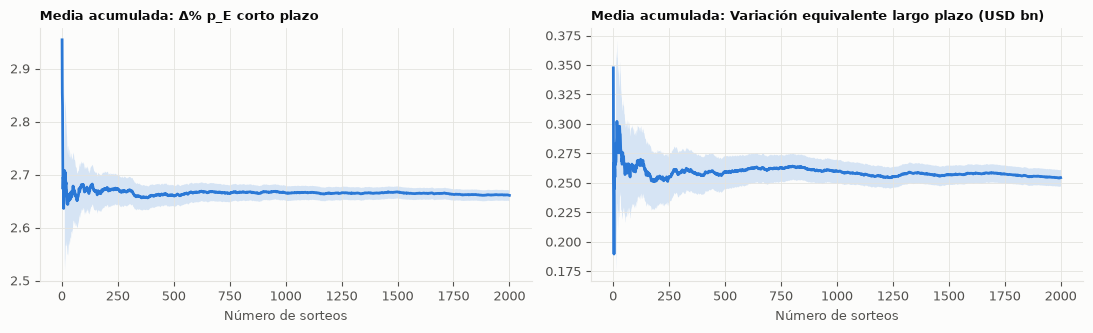

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, k in zip(ejes, ["Δ% p_E corto plazo", "Variación equivalente largo plazo (USD bn)"]):
    x = valores[k].values
    n = np.arange(1, len(x) + 1)
    media = np.cumsum(x) / n
    de = pd.Series(x).expanding().std().values
    ax.fill_between(n[10:], (media - 1.96 * de / np.sqrt(n))[10:], (media + 1.96 * de / np.sqrt(n))[10:],
                    color=AZUL, alpha=0.18, lw=0)
    ax.plot(n, media, color=AZUL)
    ax.set_title(f"Media acumulada: {k}", fontsize=9)
    ax.set_xlabel("Número de sorteos")
fig.tight_layout()
plt.show()

## I.7 Sensibilidad global: qué supuestos explican la incertidumbre

Se usan dos medidas:
- **Correlación de rangos de Spearman** entre cada parámetro y cada resultado. Capta relaciones monótonas aunque no sean lineales.
- **Coeficientes de regresión estandarizados (SRC)**, de una regresión lineal de cada resultado sobre los parámetros estandarizados.

El R² de esa regresión indica qué fracción de la varianza explica una aproximación lineal. Si el R² es alto, los SRC al cuadrado reparten la varianza entre los parámetros.

In [10]:
params = muestras.loc[valores.index]
spearman = pd.DataFrame({k: [stats.spearmanr(params[p], valores[k])[0] for p in RANGOS] for k in claves},
                        index=list(RANGOS))

Z = (params - params.mean()) / params.std()
src, r2 = {}, {}
for k in claves:
    yk = (valores[k] - valores[k].mean()) / valores[k].std()
    beta, *_ = np.linalg.lstsq(np.column_stack([np.ones(len(Z)), Z.values]), yk.values, rcond=None)
    src[k] = beta[1:]
    r2[k] = 1 - np.sum((yk.values - np.column_stack([np.ones(len(Z)), Z.values]) @ beta) ** 2) / np.sum(yk.values ** 2)
src = pd.DataFrame(src, index=list(RANGOS))
print("R² de la aproximación lineal:", {k: round(v, 3) for k, v in r2.items()})
print("\nCorrelación de rangos de Spearman (parámetro vs. resultado)")
display(spearman)
print("Coeficientes de regresión estandarizados")
src

R² de la aproximación lineal: {'Δ% p_E corto plazo': np.float64(0.998), 'Desplazamiento de consumo corto plazo (% de E_D)': np.float64(1.0), 'Δ% generación largo plazo': np.float64(0.998), 'Variación equivalente largo plazo (USD bn)': np.float64(0.962)}

Correlación de rangos de Spearman (parámetro vs. resultado)


,Δ% p_E corto plazo,Desplazamiento de consumo corto plazo (% de E_D),Δ% generación largo plazo,Variación equivalente largo plazo (USD bn)
pbi,0.0399,0.0182,0.0512,-0.0080
demanda_electrica_twh,-0.4748,-0.0044,-0.9961,-0.0020
share_electricidad_resto,0.0052,0.0170,-0.0097,-0.0077
share_trabajo_pbi,-0.0229,-0.0224,-0.0194,0.0523
share_trabajo_energia,-0.8762,-0.9999,0.0246,0.0013
elasticidad_oferta_laboral,-0.0734,-0.0429,-0.0421,0.0312
masa_salarial_usd_bn,0.0046,0.0220,-0.0097,0.0223
costo_uso_capital,0.0193,0.0030,0.0423,0.2759
markup,0.0123,-0.0089,0.0534,0.9378


Coeficientes de regresión estandarizados


,Δ% p_E corto plazo,Desplazamiento de consumo corto plazo (% de E_D),Δ% generación largo plazo,Variación equivalente largo plazo (USD bn)
pbi,-0.0007,-0.0010,0.0085,-0.0031
demanda_electrica_twh,-0.4906,0.0029,-0.9956,0.0071
share_electricidad_resto,-0.0161,0.0031,-0.0208,-0.0001
share_trabajo_pbi,-0.0136,-0.0003,-0.0379,-0.0018
share_trabajo_energia,-0.8650,-1.0004,0.0350,-0.0021
elasticidad_oferta_laboral,-0.0159,0.0113,-0.0156,0.0003
masa_salarial_usd_bn,-0.0018,0.0050,0.0042,0.0114
costo_uso_capital,0.0093,-0.0006,0.0214,0.3434
markup,0.0258,-0.0015,0.0626,0.9280


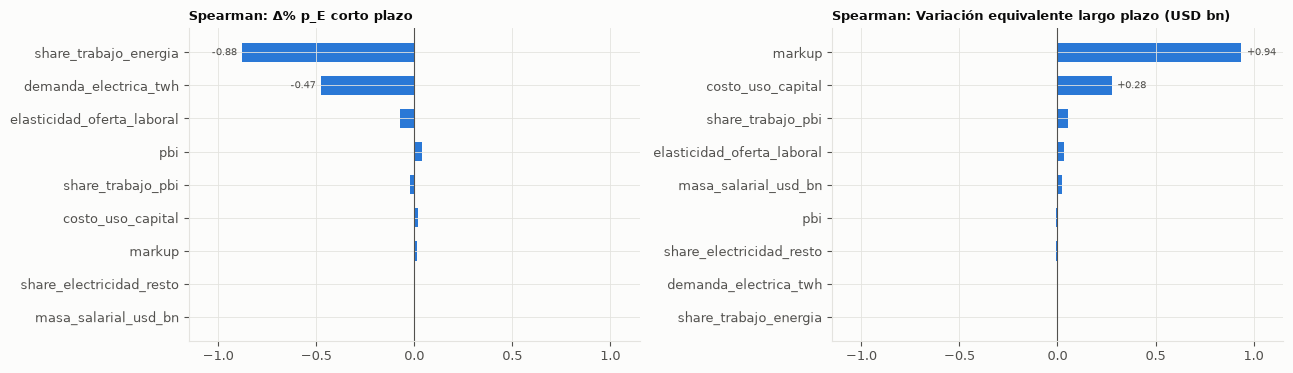

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, k in zip(ejes, ["Δ% p_E corto plazo", "Variación equivalente largo plazo (USD bn)"]):
    s = spearman[k].reindex(spearman[k].abs().sort_values().index)
    ax.barh(range(len(s)), s.values, color=AZUL, height=0.6)
    ax.set_yticks(range(len(s)), s.index)
    ax.axvline(0, color=TINTA2, lw=0.8)
    for y, v in enumerate(s.values):
        if abs(v) >= 0.1:
            ax.annotate(f"{v:+.2f}", (v, y), xytext=(4 if v > 0 else -4, 0), textcoords="offset points",
                        ha="left" if v > 0 else "right", va="center", fontsize=7.5, color=TINTA2)
    ax.set_xlim(-1.15, 1.15)
    ax.set_title(f"Spearman: {k}", fontsize=9)
fig.tight_layout()
plt.show()

## I.8 Prueba de unicidad del equilibrio

Un MEGC puede tener equilibrios múltiples. Para descartarlo en la calibración central, se resuelve el sistema desde 300 puntos iniciales aleatorios (cada precio y cantidad multiplicado por un factor de entre 0,25 y 4) y se verifica que todos converjan **al mismo** equilibrio. No es una demostración formal de unicidad, pero es la prueba numérica estándar.

In [12]:
rng = np.random.default_rng(SEMILLA)
z_base = np.log([cal_central["pE0"], 1.0, 1.0, 1.0, cal_central["XE0"], cal_central["XR0"]])
filas_u = {}
for cierre in ["corto", "largo"]:
    ref = resolver(cal_central, cierre, con_dc=True)
    z_ref = np.log([ref[k] for k in ("pE", "w", "rE", "rR", "XE", "XR")])
    convergidos, distancias = 0, []
    for _ in range(N_INICIOS):
        z0 = z_base + rng.uniform(np.log(0.25), np.log(4), size=6)
        with np.errstate(all="ignore"):  # inicios extremos pueden dar valores inválidos en pasos intermedios
            s = root(_residuos, z0, args=(cal_central, cierre, True), method="hybr", tol=1e-12)
        if s.success and np.abs(s.fun).max() < 1e-9:
            convergidos += 1
            distancias.append(np.abs(s.x - z_ref).max())
    filas_u[f"Con datacenter, {cierre} plazo"] = {
        "Puntos iniciales": N_INICIOS, "Convergen (%)": 100 * convergidos / N_INICIOS,
        "Distancia máxima al equilibrio de referencia (log)": max(distancias) if distancias else np.nan,
        "Equilibrios distintos hallados": int(np.sum(np.array(distancias) > 1e-6)) if distancias else 0}
pd.DataFrame(filas_u).T

,Puntos iniciales,Convergen (%),Distancia máxima al equilibrio de referencia (log),Equilibrios distintos hallados
"Con datacenter, corto plazo",300.0000,95.6667,0.0000,0.0000
"Con datacenter, largo plazo",300.0000,94.3333,0.0000,0.0000


---
# Parte II · SVAR

## II.1 Datos y estimación

Se usan la misma especificación y los mismos datos que en `var_enfermedad_holandesa.ipynb`: IED, energía, transable / no transable e ITCRM; dummies estacionales y de pandemia; términos del intercambio como exógenos; rezagos por Hannan-Quinn; identificación de Cholesky. El código de datos y estimación se repite acá para que este notebook no dependa de aquel.

In [13]:
API = "https://apis.datos.gob.ar/series/api/series/"
ITCRM_XLSX = "https://www.bcra.gob.ar/Pdfs/PublicacionesEstadisticas/ITCRMSerie.xlsx"
CACHE = Path("datos_var")
CACHE.mkdir(exist_ok=True)
SERIES_EMAE = {"industria": "11.3_VMASD_2004_M_23", "construccion": "11.3_VMATC_2004_M_12",
               "comercio": "11.3_AGCS_2004_M_41", "energia": "11.3_ITC_2004_M_21"}
SERIES_TRIM = {"ied_capital": "160.2_CFIN_PASINTAL_0_T_57", "ied_deuda": "160.2_CFIN_INUDA_0_T_52",
               "tot": "82.2_ITI_2004_T_27"}


def descargar(url):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=90) as r:
        return r.read()


def serie_api(ids, collapse=None):
    url = f"{API}?ids={','.join(ids.values())}&format=csv&limit=1000&start_date=2004-01-01"
    if collapse:
        url += f"&collapse={collapse}&collapse_aggregation=avg"
    df = pd.read_csv(io.BytesIO(descargar(url)), parse_dates=[0], index_col=0)
    df.columns = list(ids)
    return df


def itcrm_bcra():
    hoja = pd.read_excel(io.BytesIO(descargar(ITCRM_XLSX)), sheet_name="ITCRM y bilaterales prom. mens.",
                         header=None).iloc[:, :2]
    hoja.columns = ["fecha", "itcrm"]
    hoja["fecha"] = pd.to_datetime(hoja["fecha"], errors="coerce", format="mixed")
    s = hoja.dropna().set_index("fecha")["itcrm"].astype(float)
    q = s.resample("QS").agg(["mean", "count"])
    return q.loc[q["count"] == 3, ["mean"]].rename(columns={"mean": "itcrm"})


def cargar(nombre, funcion):
    archivo = CACHE / f"{nombre}.csv"
    try:
        df = funcion()
        df.to_csv(archivo)
        origen = "descarga"
    except Exception as e:
        if not archivo.exists():
            raise
        df = pd.read_csv(archivo, index_col=0, parse_dates=True)
        origen = f"caché local ({type(e).__name__})"
    print(f"{nombre:6s} {origen}: {df.index.min():%Y-%m} a {df.index.max():%Y-%m}")
    return df


ORDEN = ["ied", "energia", "relativo_tn", "itcrm"]
ETIQUETAS = {"ied": "IED", "energia": "Energía", "relativo_tn": "Transable / no transable", "itcrm": "ITCRM"}


def armar(datos):
    v = pd.DataFrame(index=datos.index)
    v["ied"] = (datos["ied_capital"] + datos["ied_deuda"]) / 1000
    v["energia"] = 100 * np.log(datos["energia"]).diff()
    v["relativo_tn"] = 100 * (np.log(datos["industria"])
                              - 0.5 * (np.log(datos["construccion"]) + np.log(datos["comercio"]))).diff()
    v["itcrm"] = 100 * np.log(datos["itcrm"]).diff()
    q = v.index.quarter
    x = pd.DataFrame({"q2": q == 2, "q3": q == 3, "q4": q == 4,
                      "covid_2020q2": v.index == pd.Period("2020Q2"),
                      "covid_2020q3": v.index == pd.Period("2020Q3")}, index=v.index).astype(float)
    dtot = 100 * np.log(datos["tot"]).diff()
    x["tot"], x["tot_l1"] = dtot, dtot.shift(1)
    m = pd.concat([v, x], axis=1).dropna()
    m.index = m.index.to_timestamp()
    return m[ORDEN], m[x.columns]


datos = pd.concat([cargar("emae", lambda: serie_api(SERIES_EMAE, "quarter")),
                   cargar("trim", lambda: serie_api(SERIES_TRIM)),
                   cargar("itcrm", itcrm_bcra)], axis=1, sort=True).dropna()
datos.index = pd.PeriodIndex(datos.index, freq="Q")
Y, X = armar(datos)
P = max(1, int(VAR(Y, exog=X).select_order(maxlags=4, trend="c").selected_orders["hqic"]))
res = VAR(Y, exog=X).fit(P, trend="c")
T, K = Y.shape
print(f"\nMuestra: {Y.index[0]:%Y}T{Y.index[0].quarter} a {Y.index[-1]:%Y}T{Y.index[-1].quarter} ({T} trimestres), p = {P}")

emae   descarga: 2004-01 a 2026-04


trim   descarga: 2004-01 a 2026-04


itcrm  descarga: 1997-01 a 2026-07

Muestra: 2006T3 a 2026T1 (79 trimestres), p = 1


In [14]:
def irf_ortogonal(A, Sigma, H=H):
    # Respuestas ortogonalizadas (Cholesky) a partir de los coeficientes: Theta_h = Phi_h P
    k, p = Sigma.shape[0], len(A)
    Phi = [np.eye(k)]
    for h in range(1, H + 1):
        Phi.append(sum(Phi[h - i] @ A[i - 1] for i in range(1, min(h, p) + 1)))
    Pc = np.linalg.cholesky(Sigma)
    return np.array([F @ Pc for F in Phi])


def respuesta(Theta, E):
    return np.array([sum(Theta[h - j] @ E[j] for j in range(h + 1)) for h in range(len(E))])


def fijar(Theta, E, var, objetivo, shock):
    E = E.copy()
    for h in range(len(E)):
        r = sum(Theta[h - j] @ E[j] for j in range(h + 1))
        E[h, shock] += (objetivo[h] - r[var]) / Theta[0, var, shock]
    return E


def efectos(Theta, H=H):
    # Efectos acumulados a h = H ante USD 1 bn de IED: total y canal cambiario sobre transable / no transable
    i_ied, i_q, i_tn = ORDEN.index("ied"), ORDEN.index("itcrm"), ORDEN.index("relativo_tn")
    E = np.zeros((H + 1, Theta.shape[1]))
    E[0, i_ied] = 1 / Theta[0, i_ied, i_ied]
    total = respuesta(Theta, E).cumsum(axis=0)[-1]
    sin_canal = respuesta(Theta, fijar(Theta, E, i_q, np.zeros(H + 1), i_q)).cumsum(axis=0)[-1]
    return {"ITCRM": total[i_q], "Transable / no transable": total[i_tn],
            "Canal cambiario sobre T/N": total[i_tn] - sin_canal[i_tn]}


A_hat, Sigma_hat = list(res.coefs), np.asarray(res.sigma_u)
verdad = efectos(irf_ortogonal(A_hat, Sigma_hat))
print("Efectos estimados a h=20 ante USD 1 bn de IED (%):", {k: round(v, 3) for k, v in verdad.items()})

Efectos estimados a h=20 ante USD 1 bn de IED (%): {'ITCRM': np.float64(0.355), 'Transable / no transable': np.float64(0.561), 'Canal cambiario sobre T/N': np.float64(-0.008)}


## II.2 Ajuste dentro de la muestra

Para cada ecuación del VAR:
- **R² y R² ajustado.**
- **Prueba F de los rezagos:** compara el modelo completo con uno que solo tiene constante y exógenas. H0: los rezagos de todas las variables no aportan. Si se rechaza, la dinámica del VAR explica algo más allá de la estacionalidad y los controles.
- **R² parcial de los rezagos:** fracción de la varianza residual del modelo restringido que explican los rezagos.
- **Diagnóstico de residuos:** Ljung-Box (autocorrelación, 8 rezagos), ARCH-LM (heterocedasticidad condicional, 4 rezagos) y Jarque-Bera (normalidad).

In [15]:
def matrices(Y, X, p):
    # Variable dependiente y regresores (constante, exógenas, rezagos) alineados
    lags = pd.concat([Y.shift(i).add_suffix(f"_l{i}") for i in range(1, p + 1)], axis=1)
    Z = pd.concat([pd.Series(1.0, index=Y.index, name="const"), X, lags], axis=1).iloc[p:]
    return Y.iloc[p:], Z, ["const"] + list(X.columns)


def ssr(y, Z):
    Z = Z.loc[:, Z.abs().sum() > 0]  # descarta columnas vacías (dummies fuera de la submuestra)
    b, *_ = np.linalg.lstsq(Z.values, y.values, rcond=None)
    e = y.values - Z.values @ b
    return e @ e, np.linalg.matrix_rank(Z.values), e


Yd, Zd, cols_r = matrices(Y, X, P)
filas = {}
for col in ORDEN:
    y = Yd[col]
    s_u, k_u, e = ssr(y, Zd)
    s_r, k_r, _ = ssr(y, Zd[cols_r])
    n = len(y)
    q = k_u - k_r
    F = ((s_r - s_u) / q) / (s_u / (n - k_u))
    sst = np.sum((y - y.mean()) ** 2)
    filas[ETIQUETAS[col]] = {
        "R²": 1 - s_u / sst, "R² ajustado": 1 - (s_u / (n - k_u)) / (sst / (n - 1)),
        "F rezagos": F, "p-valor F": stats.f.sf(F, q, n - k_u), "R² parcial rezagos": (s_r - s_u) / s_r,
        "Ljung-Box(8) p": acorr_ljungbox(e, lags=[8])["lb_pvalue"].iloc[0],
        "ARCH-LM(4) p": het_arch(e, nlags=4)[1],
        "Jarque-Bera p": stats.jarque_bera(e).pvalue,
    }
ajuste = pd.DataFrame(filas).T
print(f"Sistema: Portmanteau(8) p = {res.test_whiteness(nlags=8).pvalue:.3f} | "
      f"Jarque-Bera multivariada p = {res.test_normality().pvalue:.3f} | estable: {res.is_stable()}")
ajuste

Sistema: Portmanteau(8) p = 0.191 | Jarque-Bera multivariada p = 0.000 | estable: True


,R²,R² ajustado,F rezagos,p-valor F,R² parcial rezagos,Ljung-Box(8) p,ARCH-LM(4) p,Jarque-Bera p
IED,0.3496,0.2412,5.8045,0.0005,0.2602,0.8325,0.3900,0.0000
Energía,0.7225,0.6762,4.8683,0.0017,0.2278,0.3298,0.2677,0.4682
Transable / no transable,0.9529,0.9450,2.3118,0.0668,0.1229,0.4718,0.4058,0.5833
ITCRM,0.2078,0.0757,2.1998,0.0785,0.1176,0.7836,0.9088,0.0000


## II.3 Estabilidad estructural (prueba de Chow)

La muestra cruza regímenes cambiarios muy distintos. La prueba de Chow contrasta, ecuación por ecuación, si los coeficientes son iguales antes y después de un quiebre. H0: no hay quiebre. Se prueban dos fechas candidatas: **2016T1**, tras la salida del primer cepo, y **2019T4**, con el retorno del cepo.

In [16]:
filas = {}
for quiebre in ["2016-01-01", "2019-10-01"]:
    for col in ORDEN:
        y, Z = Yd[col], Zd
        s_r, k_r, _ = ssr(y, Z)
        antes, despues = y.index < quiebre, y.index >= quiebre
        s1, k1, _ = ssr(y[antes], Z[antes])
        s2, k2, _ = ssr(y[despues], Z[despues])
        n = len(y)
        F = ((s_r - (s1 + s2)) / (k1 + k2 - k_r)) / ((s1 + s2) / (n - k1 - k2))
        filas[(quiebre[:4] + "T" + str((int(quiebre[5:7]) - 1) // 3 + 1), ETIQUETAS[col])] = {
            "F de Chow": F, "p-valor": stats.f.sf(F, k1 + k2 - k_r, n - k1 - k2)}
chow = pd.DataFrame(filas).T
chow["¿Quiebre al 5%?"] = np.where(chow["p-valor"] < 0.05, "sí", "no")
chow

F de Chow  p-valor ¿Quiebre al 5%?
2016T1 IED                          1.1204   0.3638              no
       Energía                      0.9261   0.5166              no
       Transable / no transable     1.9792   0.0532              no
       ITCRM                        1.2050   0.3079              no
2019T4 IED                          1.4763   0.1728              no
       Energía                      1.9021   0.0641              no
       Transable / no transable     1.1316   0.3560              no
       ITCRM                        1.0816   0.3917              no

## II.4 Efectividad predictiva fuera de la muestra

Pronósticos a un trimestre con ventana expansiva desde 2016T1: en cada trimestre se reestima con los datos disponibles hasta el anterior y se pronostica el siguiente. El VAR se compara con dos modelos de referencia, que usan las mismas exógenas:
- **Sin dinámica:** constante + dummies + términos del intercambio.
- **AR(1):** lo anterior más el rezago de la propia variable.

Las exógenas se toman como conocidas (pronóstico condicional) en los tres modelos. Se reporta el cociente de RMSE (VAR / referencia; < 1 = el VAR pronostica mejor) y la prueba de **Diebold-Mariano** de igual precisión, con la corrección para muestras chicas de Harvey, Leybourne y Newbold. H0: igual precisión.

In [17]:
def diebold_mariano(e1, e2, h=1):
    d = e1 ** 2 - e2 ** 2
    n = len(d)
    dm = d.mean() / np.sqrt(d.var(ddof=1) / n)
    dm *= np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)  # corrección de Harvey, Leybourne y Newbold (1997)
    return dm, 2 * stats.t.sf(abs(dm), n - 1)


inicio = Y.index.get_loc(Y.index[Y.index >= "2016-01-01"][0])
errores = {m: [] for m in ("VAR", "Sin dinámica", "AR(1)")}
for t in range(inicio, T):
    Ytr, Xtr = Y.iloc[:t], X.iloc[:t]
    activas = Xtr.columns[Xtr.abs().sum() > 0]
    Xtr, x_sig = Xtr[activas], X.iloc[t:t + 1][activas]
    r = VAR(Ytr, exog=Xtr).fit(P, trend="c")
    errores["VAR"].append(Y.iloc[t].values - r.forecast(Ytr.values[-P:], 1, exog_future=x_sig.values)[0])
    e_sd, e_ar = [], []
    for col in ORDEN:
        Z0 = np.column_stack([np.ones(t), Xtr.values])
        b0, *_ = np.linalg.lstsq(Z0, Ytr[col].values, rcond=None)
        e_sd.append(Y[col].iloc[t] - np.r_[1, x_sig.values[0]] @ b0)
        Z1 = np.column_stack([Z0[1:], Ytr[col].values[:-1]])
        b1, *_ = np.linalg.lstsq(Z1, Ytr[col].values[1:], rcond=None)
        e_ar.append(Y[col].iloc[t] - np.r_[1, x_sig.values[0], Ytr[col].values[-1]] @ b1)
    errores["Sin dinámica"].append(e_sd)
    errores["AR(1)"].append(e_ar)
errores = {m: np.array(v) for m, v in errores.items()}

filas = {}
for j, col in enumerate(ORDEN):
    rmse = {m: np.sqrt(np.mean(e[:, j] ** 2)) for m, e in errores.items()}
    dm1, p1 = diebold_mariano(errores["VAR"][:, j], errores["Sin dinámica"][:, j])
    dm2, p2 = diebold_mariano(errores["VAR"][:, j], errores["AR(1)"][:, j])
    filas[ETIQUETAS[col]] = {"RMSE VAR": rmse["VAR"], "RMSE / sin dinámica": rmse["VAR"] / rmse["Sin dinámica"],
                             "DM p-valor (vs. sin dinámica)": p1, "RMSE / AR(1)": rmse["VAR"] / rmse["AR(1)"],
                             "DM p-valor (vs. AR(1))": p2}
print(f"Pronósticos evaluados: {T - inicio} trimestres ({Y.index[inicio]:%Y}T{Y.index[inicio].quarter} en adelante)")
pronostico = pd.DataFrame(filas).T
pronostico

Pronósticos evaluados: 41 trimestres (2016T1 en adelante)


,RMSE VAR,RMSE / sin dinámica,DM p-valor (vs. sin dinámica),RMSE / AR(1),DM p-valor (vs. AR(1))
IED,2.0847,0.9675,0.7701,1.0265,0.4191
Energía,3.6872,0.9227,0.1923,1.0475,0.3283
Transable / no transable,3.8666,1.0167,0.6816,1.0069,0.7247
ITCRM,8.9609,1.0593,0.4343,1.0088,0.7412


## II.5 Monte Carlo 1: sesgo del estimador en muestra finita

Con 79 trimestres, los estimadores de un VAR están sesgados: tienden a subestimar la persistencia. Para medir cuánto afecta eso a las conclusiones, se toman los coeficientes estimados como **proceso generador verdadero**, se simulan 1.000 muestras del mismo largo con innovaciones gaussianas, se reestima el VAR en cada una y se comparan los efectos estimados con los verdaderos:
- **Sesgo:** media de las estimaciones menos el valor verdadero.
- **RMSE:** error cuadrático medio.
- **Cobertura del signo:** porcentaje de réplicas con el mismo signo que el valor verdadero.

In [18]:
def simular(A, Sigma, C, Xd, Y0, rng):
    p, (n, k) = len(A), Y0.shape
    u = rng.multivariate_normal(np.zeros(k), Sigma, size=n - p)
    ys = Y0.copy()
    for t in range(p, n):
        ys[t] = C @ Xd[t] + sum(A[i] @ ys[t - 1 - i] for i in range(p)) + u[t - p]
    return pd.DataFrame(ys, index=Y.index, columns=ORDEN)


Xd = np.column_stack([np.ones(T), X.values])
C_hat = res.coefs_exog
rng = np.random.default_rng(SEMILLA)
t0 = time.time()
est_mc = []
for _ in range(N_MC_SESGO):
    rb = VAR(simular(A_hat, Sigma_hat, C_hat, Xd, Y.values, rng), exog=X).fit(P, trend="c")
    est_mc.append(efectos(irf_ortogonal(list(rb.coefs), np.asarray(rb.sigma_u))))
est_mc = pd.DataFrame(est_mc)
print(f"{N_MC_SESGO} réplicas en {time.time() - t0:.1f} s")
sesgo = pd.DataFrame({
    "Verdadero (estimado con datos)": pd.Series(verdad),
    "Media de las estimaciones": est_mc.mean(),
    "Sesgo": est_mc.mean() - pd.Series(verdad),
    "Sesgo relativo (%)": 100 * (est_mc.mean() - pd.Series(verdad)) / pd.Series(verdad).abs(),
    "RMSE": np.sqrt(((est_mc - pd.Series(verdad)) ** 2).mean()),
    "Mismo signo (%)": 100 * (np.sign(est_mc) == np.sign(pd.Series(verdad))).mean(),
})
sesgo

1000 réplicas en 9.5 s


,Verdadero (estimado con datos),Media de las estimaciones,Sesgo,Sesgo relativo (%),RMSE,Mismo signo (%)
ITCRM,0.3552,0.3893,0.0341,9.6007,1.0862,64.9000
Transable / no transable,0.5607,0.5546,-0.0061,-1.0800,0.2935,97.1000
Canal cambiario sobre T/N,-0.0080,-0.0074,0.0006,7.0649,0.0540,53.3000


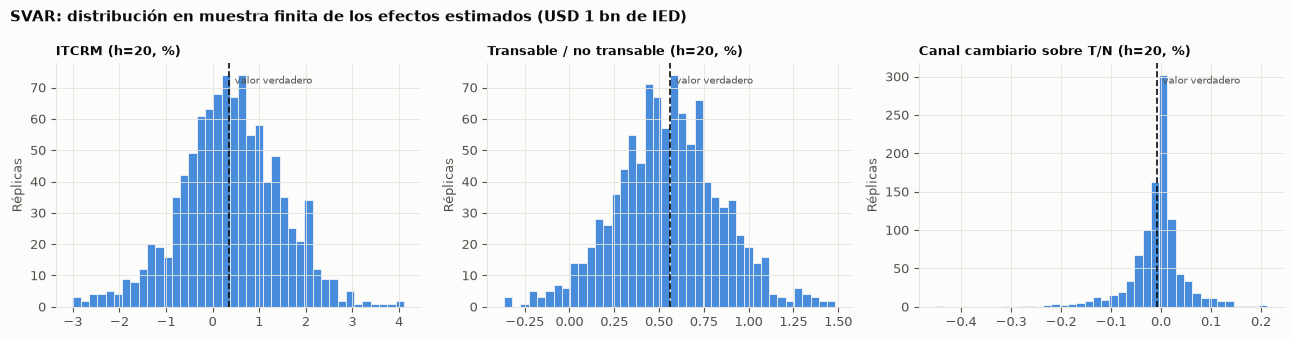

In [19]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, k in zip(ejes, est_mc.columns):
    ax.hist(est_mc[k], bins=40, color=AZUL, alpha=0.85, edgecolor=FONDO, linewidth=0.6)
    ax.axvline(verdad[k], color=TINTA, lw=1.2, ls="--")
    ax.annotate("valor verdadero", (verdad[k], ax.get_ylim()[1] * 0.95), xytext=(4, 0), textcoords="offset points",
                fontsize=7.5, color=TINTA2, va="top")
    ax.set_title(f"{k} (h=20, %)", fontsize=9)
    ax.set_ylabel("Réplicas")
fig.suptitle("SVAR: distribución en muestra finita de los efectos estimados (USD 1 bn de IED)", x=0.01, ha="left",
             fontweight="bold", color=TINTA)
fig.tight_layout()
plt.show()

## II.6 Monte Carlo 2: tamaño y potencia, ¿podría el SVAR detectar una enfermedad holandesa?

El SVAR no encontró un efecto significativo de la IED sobre el tipo de cambio real. Ese "no hallazgo" solo es informativo si el test tiene **potencia**: si existiera enfermedad holandesa, ¿la habría detectado con 79 trimestres?

Diseño:
1. Se modifica el proceso estimado: se anula el efecto contemporáneo de la IED sobre el ITCRM (en el factor de Cholesky de $\Sigma_u$) y se fija su efecto rezagado en $A_1[q, \text{IED}] = \delta$. Con $\delta = 0$ la IED no afecta directamente al tipo de cambio (hipótesis nula verdadera). Con $\delta < 0$, la IED aprecia el tipo de cambio real (enfermedad holandesa).
2. Para cada $\delta$ se simulan 1.000 muestras y se aplica la prueba de causalidad de Granger IED → ITCRM al 5%.
3. Con $\delta = 0$, la tasa de rechazo mide el **tamaño** real del test (debería ser ≈ 5%). Con $\delta < 0$, mide la **potencia**.

El eje horizontal se expresa como el efecto acumulado verdadero sobre el ITCRM a 5 años, calculado con el propio proceso simulado, para compararlo con el efecto estimado con los datos.

In [20]:
i_q, i_ied = ORDEN.index("itcrm"), ORDEN.index("ied")
deltas = [0.0, -0.25, -0.5, -0.75, -1.0, -1.5, -2.0, -3.0]
rng = np.random.default_rng(SEMILLA + 1)
t0 = time.time()
filas = []
for d in deltas:
    A_d = [a.copy() for a in A_hat]
    for a in A_d[1:]:
        a[i_q, i_ied] = 0.0
    A_d[0][i_q, i_ied] = d
    Pc = np.linalg.cholesky(Sigma_hat)
    Pc[i_q, i_ied] = 0.0                      # sin efecto contemporáneo de la IED sobre el ITCRM
    Sigma_d = Pc @ Pc.T
    efecto_verdadero = efectos(irf_ortogonal(A_d, Sigma_d))["ITCRM"]
    rechazos = 0
    for _ in range(N_MC_POTENCIA):
        rb = VAR(simular(A_d, Sigma_d, C_hat, Xd, Y.values, rng), exog=X).fit(P, trend="c")
        rechazos += rb.test_causality("itcrm", "ied", kind="f").pvalue < 0.05
    filas.append({"δ (efecto rezagado)": d, "Efecto acumulado verdadero sobre el ITCRM a h=20 (%)": efecto_verdadero,
                  "Tasa de rechazo al 5%": rechazos / N_MC_POTENCIA})
potencia = pd.DataFrame(filas)
print(f"{len(deltas) * N_MC_POTENCIA} réplicas en {time.time() - t0:.1f} s")
print(f"Granger IED → ITCRM con los datos reales: p = {res.test_causality('itcrm', 'ied', kind='f').pvalue:.3f}")
potencia

8000 réplicas en 50.6 s
Granger IED → ITCRM con los datos reales: p = 0.191


,δ (efecto rezagado),Efecto acumulado verdadero sobre el ITCRM a h=20 (%),Tasa de rechazo al 5%
0,0.0000,-0.4523,0.0500
1,-0.2500,-0.9964,0.0930
2,-0.5000,-1.5544,0.1880
3,-0.7500,-2.1268,0.3880
4,-1.0000,-2.7142,0.6200
5,-1.5000,-3.9362,0.9090
6,-2.0000,-5.2257,0.9890
7,-3.0000,-8.0304,1.0000


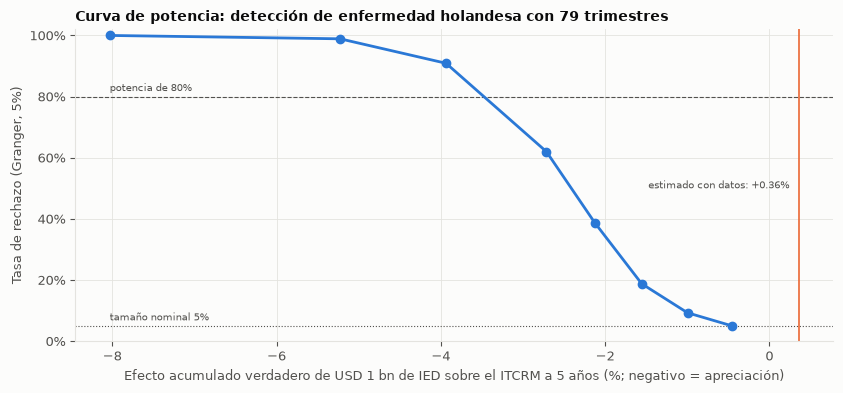

Efecto mínimo detectable con 80% de potencia: una apreciación acumulada de 3.94% por USD 1 bn de IED a 5 años.


In [21]:
fig, ax = plt.subplots(figsize=(8.5, 4))
x = potencia["Efecto acumulado verdadero sobre el ITCRM a h=20 (%)"]
yv = potencia["Tasa de rechazo al 5%"]
ax.axhline(0.05, color=TINTA2, lw=0.8, ls=":")
ax.axhline(0.80, color=TINTA2, lw=0.8, ls="--")
ax.annotate("tamaño nominal 5%", (x.min(), 0.05), xytext=(0, 4), textcoords="offset points", fontsize=7.5, color=TINTA2)
ax.annotate("potencia de 80%", (x.min(), 0.80), xytext=(0, 4), textcoords="offset points", fontsize=7.5, color=TINTA2)
ax.plot(x, yv, color=AZUL, marker="o", markersize=6)
ax.axvline(verdad["ITCRM"], color=NARANJA, lw=1.2)
ax.annotate(f"estimado con datos: {verdad['ITCRM']:+.2f}%", (verdad["ITCRM"], 0.5), xytext=(-6, 0),
            textcoords="offset points", ha="right", fontsize=7.5, color=TINTA2)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Efecto acumulado verdadero de USD 1 bn de IED sobre el ITCRM a 5 años (%; negativo = apreciación)")
ax.set_ylabel("Tasa de rechazo (Granger, 5%)")
ax.set_title("Curva de potencia: detección de enfermedad holandesa con 79 trimestres")
fig.tight_layout()
plt.show()

alcanza = potencia[potencia["Tasa de rechazo al 5%"] >= 0.80]
if len(alcanza):
    mde = alcanza.iloc[0]["Efecto acumulado verdadero sobre el ITCRM a h=20 (%)"]
    print(f"Efecto mínimo detectable con 80% de potencia: una apreciación acumulada de {abs(mde):.2f}% "
          f"por USD 1 bn de IED a 5 años.")
else:
    print("Ningún tamaño de efecto de la grilla alcanza 80% de potencia.")

---
# Parte III · Resumen de pruebas

In [22]:
fmt_p = lambda p: f"p = {p:.3f}"
resumen = pd.DataFrame([
    ["MEGC", "Replicación del año base (todos los sorteos)", f"{validacion['Sorteos que aprueban (%)'].iloc[0]:.1f}% aprueba", "Validez numérica"],
    ["MEGC", "Ley de Walras (todos los sorteos)", f"{validacion['Sorteos que aprueban (%)'].iloc[1]:.1f}% aprueba", "Consistencia contable"],
    ["MEGC", "Unicidad del equilibrio (300 inicios)",
     f"{int(pd.DataFrame(filas_u).T['Equilibrios distintos hallados'].sum())} equilibrios distintos", "Unicidad numérica"],
    ["MEGC", "Signo de Δ% p_E de corto plazo", f"P(>0) = {resumen_megc.loc['Δ% p_E corto plazo', 'P(> 0)']:.3f}",
     "Robustez a los supuestos"],
    ["MEGC", "Signo de la variación equivalente de largo plazo",
     f"P(>0) = {resumen_megc.loc['Variación equivalente largo plazo (USD bn)', 'P(> 0)']:.3f}", "Robustez a los supuestos"],
    ["SVAR", "Prueba F de los rezagos (ecuación T/N)", fmt_p(ajuste.loc["Transable / no transable", "p-valor F"]),
     "Ajuste dentro de la muestra"],
    ["SVAR", "Portmanteau multivariada (8 rezagos)", fmt_p(res.test_whiteness(nlags=8).pvalue), "Especificación"],
    ["SVAR", "Chow con quiebre en 2019T4 (ecuaciones con p < 0,05)",
     f"{int((chow.xs('2019T4')['p-valor'] < 0.05).sum())} de 4", "Estabilidad"],
    ["SVAR", "Cociente de RMSE VAR / AR(1) (promedio de las 4 ecuaciones)",
     f"{pronostico['RMSE / AR(1)'].mean():.3f}", "Pronóstico fuera de muestra"],
    ["SVAR", "Diebold-Mariano vs. AR(1): ecuaciones con p < 0,05",
     f"{int((pronostico['DM p-valor (vs. AR(1))'] < 0.05).sum())} de 4", "Pronóstico fuera de muestra"],
    ["SVAR", "Tamaño real del test de Granger (δ = 0)", f"{potencia.iloc[0, 2]:.1%}", "Tamaño (nominal 5%)"],
    ["SVAR", "Potencia ante una apreciación de 1% por USD 1 bn",
     f"{np.interp(-1.0, potencia.iloc[:, 1].values[::-1], potencia.iloc[:, 2].values[::-1]):.1%}", "Potencia"],
    ["SVAR", "Efecto mínimo detectable con 80% de potencia",
     f"{abs(potencia[potencia.iloc[:, 2] >= 0.8].iloc[0, 1]):.2f}% de apreciación por USD 1 bn"
     if (potencia.iloc[:, 2] >= 0.8).any() else "no alcanzado", "Potencia"],
], columns=["Modelo", "Prueba", "Resultado", "Qué valida"])
resumen

,Modelo,Prueba,Resultado,Qué valida
0,MEGC,Replicación del año base (todos los sorteos),100.0% aprueba,Validez numérica
1,MEGC,Ley de Walras (todos los sorteos),100.0% aprueba,Consistencia contable
2,MEGC,Unicidad del equilibrio (300 inicios),0 equilibrios distintos,Unicidad numérica
3,MEGC,Signo de Δ% p_E de corto plazo,P(>0) = 1.000,Robustez a los supuestos
4,MEGC,Signo de la variación equivalente de largo plazo,P(>0) = 1.000,Robustez a los supuestos
5,SVAR,Prueba F de los rezagos (ecuación T/N),p = 0.067,Ajuste dentro de la muestra
6,SVAR,Portmanteau multivariada (8 rezagos),p = 0.191,Especificación
7,SVAR,"Chow con quiebre en 2019T4 (ecuaciones con p < 0,05)",0 de 4,Estabilidad
8,SVAR,Cociente de RMSE VAR / AR(1) (promedio de las 4 ecuaciones),1.022,Pronóstico fuera de muestra
9,SVAR,"Diebold-Mariano vs. AR(1): ecuaciones con p < 0,05",0 de 4,Pronóstico fuera de muestra


## Conclusiones

Resultados de la ejecución del 27/10/2026, con semilla 42. Las cifras del MEGC son reproducibles exactamente. Las del SVAR pueden cambiar levemente si INDEC o el BCRA publican datos nuevos.

### MEGC walrasiano

**1. El modelo es numéricamente válido en todo el rango de supuestos.** En los 2.000 sorteos se cumplen la replicación del año base, la ley de Walras y la convergencia del solver (100%). La prueba de unicidad, con 300 puntos iniciales por cierre, no encontró ningún equilibrio alternativo. El ~5% de los inicios que no converge parte de valores extremos y no lleva a otra solución.

*Corrección aplicada al modelo:* el Monte Carlo detectó que `resolver` daba por fallidos 19 sorteos (≈1%) que sí habían llegado a la solución, con residuo de 2·10<sup>-16</sup>. El solver informaba "sin avances" justamente porque ya estaba en el equilibrio. Se corrigió en `stargate_cge.ipynb` para aceptar la solución cuando el residuo es menor a 10<sup>-10</sup>. `test_cge.ipynb` sigue aprobando 4 de 4.

**2. Las conclusiones principales son robustas a la incertidumbre de calibración.** El intervalo del 90% excluye el cero en:
- Suba del precio de la energía en el corto plazo: +2,66% [+2,29; +3,05].
- Desplazamiento de consumo en el corto plazo: el 80% de la demanda del datacenter se cubre quitándoles electricidad a hogares y empresas [71%; 89%].
- Generación de largo plazo: +3,22% [+3,02; +3,44].
- PBI de largo plazo: +0,89% [+0,56; +1,27].
- Producto del resto de la economía: −0,07% [−0,09; −0,06].
- Variación equivalente de largo plazo: +0,25 bn [+0,03; +0,55], positiva en el 100% de los sorteos.

**3. El efecto de largo plazo sobre el precio de la energía no es robusto:** +0,005% [−0,006; +0,018], positivo solo en el 75% de los sorteos. Es consistente con la conclusión del modelo: en el largo plazo el precio vuelve prácticamente a su nivel base.

**4. Pocos supuestos concentran la incertidumbre.** Una aproximación lineal explica entre el 96% y el 100% de la varianza (R²).
- **Suba del precio y desplazamiento de corto plazo:** dependen de la participación del trabajo en la generación (Spearman −0,88 y −1,00), que fija la elasticidad de oferta eléctrica de corto plazo, y del tamaño del sistema eléctrico (−0,47).
- **Bienestar:** depende casi por completo del margen del datacenter (+0,94) y del costo de uso del hardware (+0,28), porque la ganancia del país viene de Ganancias sobre el beneficio del datacenter.

Prioridad de datos: la estructura de costos de la generación y el margen esperado del datacenter.

### SVAR

**5. Ajuste dentro de la muestra aceptable.** Los rezagos son conjuntamente significativos en las ecuaciones de IED (p = 0,0005) y energía (p = 0,002), y marginales en transable / no transable (p = 0,067) e ITCRM (p = 0,079). El R² alto de transable / no transable (0,95) viene sobre todo de la estacionalidad; los rezagos aportan un R² parcial de 0,12.
- **Residuos:** sin autocorrelación (Ljung-Box p > 0,3; Portmanteau p = 0,19) y sin heterocedasticidad condicional (ARCH p > 0,26).
- **Normalidad:** se rechaza en las ecuaciones de IED e ITCRM, lo que justifica las bandas por bootstrap del notebook del SVAR.

**6. Coeficientes estables.** La prueba de Chow no rechaza la estabilidad al 5% en ninguna ecuación, ni con quiebre en 2016T1 ni en 2019T4. Los casos más cercanos son transable / no transable en 2016 (p = 0,053) y energía en 2019 (p = 0,064).

**7. Sin ganancia predictiva.** Fuera de la muestra (41 trimestres desde 2016T1), el VAR no pronostica mejor que los modelos de referencia. Los cocientes de RMSE van de 0,92 a 1,06, y Diebold-Mariano no rechaza la igualdad de precisión en ninguna ecuación. El valor del SVAR es estructural (descomponer canales), no predictivo.

**8. Sesgo de muestra finita pequeño, pero el signo del efecto cambiario es incierto.** El sesgo es de −1% sobre la respuesta transable / no transable y de +0,03 puntos sobre el ITCRM. Sin embargo, el signo estimado del efecto sobre el ITCRM coincide con el verdadero solo en el 65% de las réplicas (97% en transable / no transable). Con 79 trimestres, la **dirección** del efecto cambiario estimada no es informativa por sí sola.

**9. El test tiene el tamaño correcto, pero poca potencia ante efectos chicos.** Con la hipótesis nula verdadera, Granger rechaza el 5,0% de las veces (nominal 5%).
- **Potencia ante efectos chicos:** con una apreciación de 1% por USD 1 bn la potencia es del 9%.
- **Potencia ante efectos grandes:** el 80% recién se alcanza con una apreciación acumulada de ≈3,9% por USD 1 bn.
- **Nota sobre el eje del gráfico:** con δ = 0 el efecto total verdadero es −0,45%, porque queda un canal indirecto a través de energía y transable / no transable que Granger no contrasta.

**Cómo leer el resultado del SVAR.** El "no hay enfermedad holandesa" significa que los datos **descartan apreciaciones grandes** inducidas por la IED (≳4% por USD 1 bn), pero **no pueden descartar efectos chicos** (≲1,5% por USD 1 bn). El intervalo bootstrap del notebook del SVAR ([−1,42%; +2,17%]) va en la misma dirección.
